# 实验三：Seaborn 与 Pyecharts 综合绘图实践

**数据**：`nuannuan_2025.csv`，8 家门店 × 365 天 = 2920 行（utf-8-sig）。

| 列 | 含义 |
|---|---|
| 日期 / 月份 / 季节 / 天气 | 时间与天气 |
| 门店 / 区域 / 主推品类 | 组织与品类 |
| 气温 / 是否促销 | 环境与活动 |
| 销售额 / 订单数 / 客单价 / 会员订单占比 | 经营指标 |

**路线**：T1–T4（Seaborn）回答“为什么”，T5–T8（Pyecharts）回答“怎么看”，综合任务合成看板。输出均在 `exp3_assets/`。

## 0. 环境准备与全局样式（全实验共用）

In [1]:
# ===== 0.1 导入与全局样式：中文字体、虚线网格、统一配色 =====
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from pyecharts import options as opts
from pyecharts.charts import Line, Bar, Pie, Scatter, HeatMap, Radar, Page
from pyecharts.globals import ThemeType

# 中文字体：不设置会出现方框；负号单独关闭 Unicode 减号（气温有负值）
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.3
sns.set_theme(style='whitegrid', font='Microsoft YaHei')

# 统一语义色：区域色映射在所有 Seaborn / Pyecharts 图中保持一致
REGION_COLORS = {'城区': '#2563EB', '文教区': '#10B981', '新城': '#F59E0B', '枢纽': '#8B5CF6'}
CAT_COLORS = {'咖啡': '#8B5E3C', '甜品': '#F472B6', '轻食': '#10B981', '周边': '#2563EB'}
NAVY, AMBER, BLUE = '#1E3A8A', '#F59E0B', '#2563EB'

OUT = Path('exp3_assets'); OUT.mkdir(exist_ok=True)   # 图表输出目录
print('输出目录:', OUT.resolve())

输出目录: C:\Users\LENOVN\Desktop\实验三\exp3_assets


In [2]:
# ===== 0.2 读取数据 + 派生字段 =====
df = pd.read_csv('nuannuan_2025.csv', encoding='utf-8-sig')
df['日期'] = pd.to_datetime(df['日期'])
df['月份标签'] = df['月份'].map('{:.0f}月'.format)

# 门店按“区域 → 门店”固定顺序排列，保证 T2 小提琴图、T6 柱图、p5 热力图口径一致
STORE_ORDER = ['中央店', '江滨店', '老街店', '大学城店', '高新店', '万达店', '湖畔店', '机场店']
REGION_ORDER = ['城区', '文教区', '新城', '枢纽']

assert df.shape == (2920, 14) and df['销售额'].notna().all()
print(f'数据规模: {df.shape[0]} 行 × {df.shape[1]} 列')
print(f'日期范围: {df.日期.min():%Y-%m-%d} ~ {df.日期.max():%Y-%m-%d} | 门店 {df.门店.nunique()} 家 | 区域 {df.区域.nunique()} 个')
print(f'销售额合计 {df.销售额.sum()/1e4:.1f} 万元 | 日均 {df.销售额.mean():.0f} 元 | 气温 {df.气温.min()}~{df.气温.max()} ℃')
pd.DataFrame({'类型': df.dtypes.astype(str)}).T

数据规模: 2920 行 × 14 列
日期范围: 2025-01-01 ~ 2025-12-31 | 门店 8 家 | 区域 4 个
销售额合计 2169.9 万元 | 日均 7431 元 | 气温 -13.4~35.0 ℃


,日期,门店,区域,主推品类,月份,季节,天气,气温,是否促销,销售额,订单数,会员订单占比,客单价,月份标签
类型,datetime64[ns],object,object,object,int64,object,object,float64,object,float64,int64,float64,float64,object


## 任务 1 · 销售额分布（histplot，分布图）

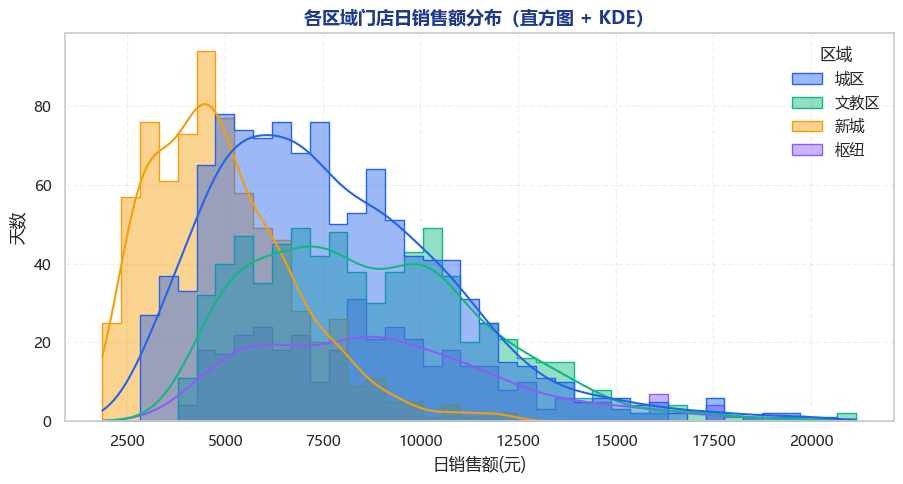

         均值     标准差     P25      P75     IQR
区域                                          
城区   7757.9  3025.6  5424.5   9558.6  4134.0
文教区  8716.7  2965.9  6384.6  10543.1  4159.0
新城   4911.2  1844.8  3465.1   6009.7  2545.0
枢纽   8920.3  3118.8  6380.2  10865.0  4485.0


In [3]:
# ===== T1：按「区域」分组的日销售额直方图 + KDE =====
plt.figure(figsize=(9.2, 5.0))
ax = sns.histplot(data=df, x='销售额', hue='区域', palette=REGION_COLORS,
                  bins=40, kde=True, element='step', fill=True, alpha=0.45)
ax.set_title('各区域门店日销售额分布（直方图 + KDE）', fontsize=13, fontweight='bold', color=NAVY)
ax.set_xlabel('日销售额(元)'); ax.set_ylabel('天数')
ax.grid(True, linestyle='--', alpha=0.3)
sns.move_legend(ax, 'upper right', frameon=False, title='区域')
plt.tight_layout()

plt.savefig(OUT / 't1_hist_sales.png', dpi=300, bbox_inches='tight')
plt.show()

# 定量佐证：均值看“整体高低”，标准差与四分位间距看“分布宽窄”
stat = df.groupby('区域')['销售额'].agg(均值='mean', 标准差='std',
                                     P25=lambda s: s.quantile(.25), P75=lambda s: s.quantile(.75))
stat['IQR'] = (stat.P75 - stat.P25).round(0)
print(stat.round(1).loc[REGION_ORDER].to_string())

**分析**：枢纽 8920 > 文教区 8717 > 城区 7758 > 新城 4911 元/日。新城最低且最窄（σ≈1845），枢纽/城区/文教区高位但波动大（σ≈3000）；单店差异被区域均值掩盖，需看 T2。

## 任务 2 · 门店销售额分布（violinplot，小提琴图）

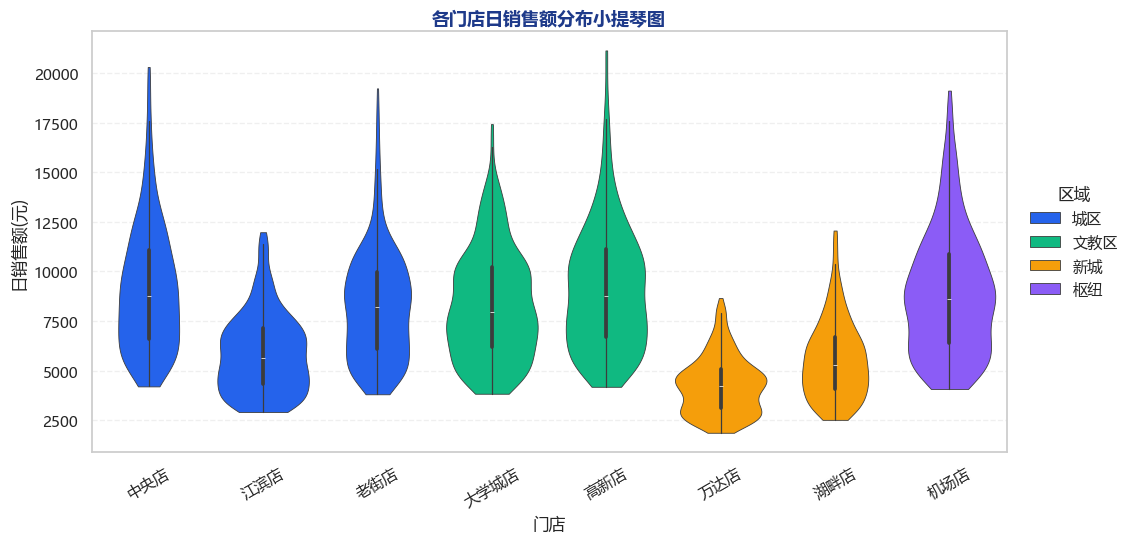

门店
中央店     8750.0
江滨店     5613.0
老街店     8224.0
大学城店    7938.0
高新店     8741.0
万达店     4196.0
湖畔店     5303.0
机场店     8604.0


In [4]:
# ===== T2：8 家门店并列小提琴图，hue=区域，inner='box' 叠加四分位 =====
plt.figure(figsize=(11.5, 5.6))
ax = sns.violinplot(data=df, x='门店', y='销售额', hue='区域', palette=REGION_COLORS,
                    order=STORE_ORDER, cut=0, inner='box', linewidth=0.6, saturation=1)
ax.set_title('各门店日销售额分布小提琴图', fontsize=13, fontweight='bold', color=NAVY)
ax.set_xlabel('门店'); ax.set_ylabel('日销售额(元)')
ax.tick_params(axis='x', rotation=30)
ax.grid(True, axis='y', linestyle='--', alpha=0.3)
sns.move_legend(ax, 'center left', bbox_to_anchor=(1.01, .5), frameon=False, title='区域')
plt.tight_layout()

plt.savefig(OUT / 't2_violin_store.png', dpi=300, bbox_inches='tight')
plt.show()

med = df.groupby('门店')['销售额'].median().round(0)
print(med.loc[STORE_ORDER].to_string())

**分析**：中位 中央店 8750 ≈ 高新店 8741 > 机场店 8604 > 老街店 8224 > 大学城店 7938 > 江滨店 5613 > 湖畔店 5303 > 万达店 4196。万达店整体压低且密度峰单薄，属结构性弱店；新城的宽尾来自湖畔/万达的落差。

## 任务 3 · 气温—销售额关系（regplot，回归关系图）

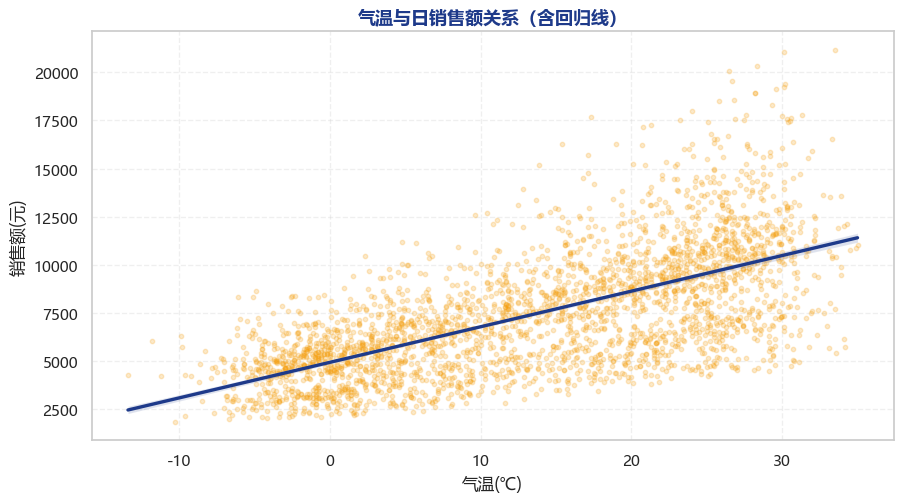

回归: 销售额 = 184.8 × 气温 + 4940   (r = 0.651)
每升高 1℃ ≈ 日销售额 +185 元；0℃ 与 30℃ 的预测差 ≈ 5544 元


In [5]:
# ===== T3：散点 + 线性回归拟合线 =====
plt.figure(figsize=(9.2, 5.2))
ax = sns.regplot(data=df, x='气温', y='销售额',
                 scatter_kws={'s': 10, 'alpha': 0.22, 'color': AMBER},
                 line_kws={'color': NAVY, 'lw': 2.4})
ax.set_title('气温与日销售额关系（含回归线）', fontsize=13, fontweight='bold', color=NAVY)
ax.set_xlabel('气温(℃)'); ax.set_ylabel('销售额(元)')
ax.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()

plt.savefig(OUT / 't3_reg_temp_sales.png', dpi=300, bbox_inches='tight')
plt.show()

# 斜率与相关系数：直观回应“气温越高、冷饮越旺”
x, y = df['气温'], df['销售额']
slope, intercept = np.polyfit(x, y, 1)
print(f'回归: 销售额 = {slope:.1f} × 气温 + {intercept:.0f}   (r = {x.corr(y):.3f})')
print(f'每升高 1℃ ≈ 日销售额 +{slope:.0f} 元；0℃ 与 30℃ 的预测差 ≈ {slope*30:.0f} 元')

**分析**：斜率 +184 元/℃、r = 0.651，气温越高卖得越多，符合直觉。散点为楔形：高温端均值抬升、离散度同时放大。

## 任务 4 · 数值变量相关性（heatmap，热力图）

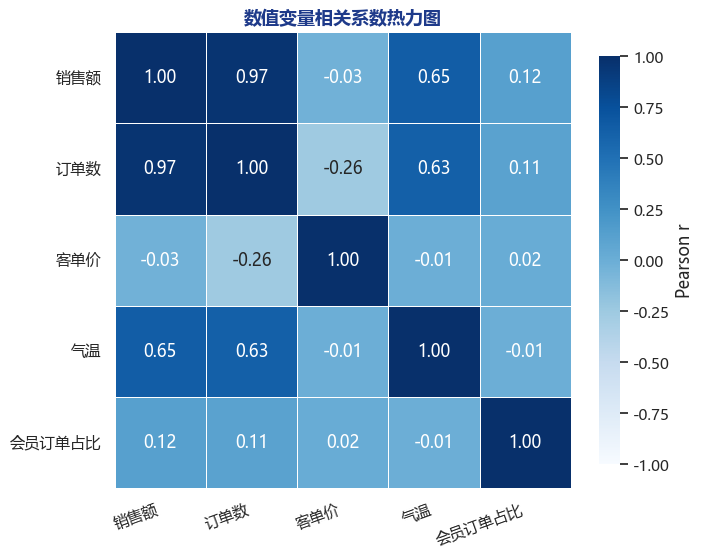

          销售额    订单数    客单价     气温  会员订单占比
销售额     1.000  0.966 -0.026  0.651   0.117
订单数     0.966  1.000 -0.257  0.627   0.107
客单价    -0.026 -0.257  1.000 -0.008   0.018
气温      0.651  0.627 -0.008  1.000  -0.006
会员订单占比  0.117  0.107  0.018 -0.006   1.000


In [6]:
# ===== T4：5 个数值变量的相关系数热力图 =====
cols = ['销售额', '订单数', '客单价', '气温', '会员订单占比']
corr = df[cols].corr()

plt.figure(figsize=(7.2, 6.0))
ax = sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues', square=True,
                 vmin=-1, vmax=1, linewidths=0.5, linecolor='white',
                 cbar_kws={'shrink': .82, 'label': 'Pearson r'})
ax.set_title('数值变量相关系数热力图', fontsize=13, fontweight='bold', color=NAVY)
plt.xticks(rotation=20, ha='right'); plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(OUT / 't4_corr_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

print(corr.round(3).to_string())

**分析**：销售额↔订单数 0.966 最强，↔气温 0.651 次之；客单价几乎无关（−0.026），且与订单数负相关（−0.257，量价替代）；会员占比近似独立（0.117）。营收是客流驱动型；相关不等于因果。

## 任务 5 · 月度销售趋势（Pyecharts Line + DataZoom）

In [7]:
# ===== T5：各区域 12 个月销售额折线，底部滑块缩放 =====
monthly = df.pivot_table(index='月份', columns='区域', values='销售额', aggfunc='sum')[REGION_ORDER]
month_x = [f'{m}月' for m in monthly.index]

line = Line(init_opts=opts.InitOpts(theme=ThemeType.MACARONS, width='100%', height='500px'))
line.add_xaxis(month_x)
for rg in REGION_ORDER:
    line.add_yaxis(
        series_name=rg,
        y_axis=monthly[rg].round(0).tolist(),
        color=REGION_COLORS[rg], symbol='circle', symbol_size=6,
        is_smooth=True, is_symbol_show=True,
        label_opts=opts.LabelOpts(is_show=False),
    )
line.set_global_opts(
    title_opts=opts.TitleOpts(title='各区域月度销售额趋势（可缩放）', subtitle='暖暖咖啡 2025 · 8 家门店'),
    tooltip_opts=opts.TooltipOpts(trigger='axis', axis_pointer_type='cross'),
    legend_opts=opts.LegendOpts(pos_top='13%', pos_left='center'),
    xaxis_opts=opts.AxisOpts(name='月份', boundary_gap=False),
    yaxis_opts=opts.AxisOpts(name='销售额(元)', splitline_opts=opts.SplitLineOpts(is_show=True)),
    datazoom_opts=[opts.DataZoomOpts(type_='slider', range_start=0, range_end=100, pos_bottom='2%'),
                   opts.DataZoomOpts(type_='inside', range_start=0, range_end=100)],
    toolbox_opts=opts.ToolboxOpts(is_show=True),
)
line.render(str(OUT / 'p1_line.html'))
print('已导出', OUT / 'p1_line.html')

season = df.groupby('月份')['销售额'].sum()
print(f'全年峰值 {season.idxmax()} 月 ({season.max()/1e4:.1f} 万)，谷值 {season.idxmin()} 月 ({season.min()/1e4:.1f} 万)')
print('各区域峰值月份:', monthly.idxmax().to_dict())

已导出 exp3_assets\p1_line.html
全年峰值 7 月 (257.4 万)，谷值 2 月 (110.3 万)
各区域峰值月份: {'城区': 7, '文教区': 7, '新城': 8, '枢纽': 7}


**分析**：四区域节奏一致：1–2 月低平 → 3–5 月陡升 → 6–8 月平台（7 月峰 257.4 万）→ 9–12 月回落（2 月谷 110.3 万），季节性由气温主导，区域间只差幅度。DataZoom 可框选旺季区间下钻。

## 任务 6 · 门店销售额（Pyecharts Bar + 标签 + 最大值标注）

In [8]:
# ===== T6：各门店全年总销售额柱状图（万元），柱顶标签 + max 标注 =====
store_sales = df.groupby('门店')['销售额'].sum().reindex(STORE_ORDER).sort_values(ascending=False)

bar = (
    Bar(init_opts=opts.InitOpts(theme=ThemeType.MACARONS, width='100%', height='460px'))
    .add_xaxis(store_sales.index.tolist())
    .add_yaxis(
        '总销售额',
        (store_sales / 1e4).round(1).tolist(),          # 换算成万元，柱顶标签才不拥挤
        label_opts=opts.LabelOpts(is_show=True, position='top', formatter='{c} 万'),
        itemstyle_opts=opts.ItemStyleOpts(color=BLUE),
    )
    .set_series_opts(markpoint_opts=opts.MarkPointOpts(
        symbol_size=34,
        data=[opts.MarkPointItem(type_='max', name='最高门店', symbol_offset=[0, -16],
                                 label_opts=opts.LabelOpts(formatter='最高', font_size=9,
                                                           position='top', distance=2))]))
    .set_global_opts(
        title_opts=opts.TitleOpts(title='各门店全年总销售额', subtitle='橙色标注为最高门店'),
        tooltip_opts=opts.TooltipOpts(trigger='axis', axis_pointer_type='shadow'),
        legend_opts=opts.LegendOpts(is_show=False),
        xaxis_opts=opts.AxisOpts(name='门店', axislabel_opts=opts.LabelOpts(rotate=20)),
        yaxis_opts=opts.AxisOpts(name='总销售额(万元)', max_=400),
        toolbox_opts=opts.ToolboxOpts(is_show=True),
    )
)
bar.render(str(OUT / 'p2_bar.html'))
print('已导出', OUT / 'p2_bar.html')
print(store_sales.round(0).to_string())

已导出 exp3_assets\p2_bar.html
门店
中央店     3336081.0
高新店     3332755.0
机场店     3255926.0
大学城店    3030431.0
老街店     3015188.0
江滨店     2143678.0
湖畔店     2031760.0
万达店     1553421.0


**分析**：中央店 333.6 万最高，高新 333.3、机场 325.6 紧随；万达 155.3 万最低，高低相差 2.15 倍。与 T2 中位排序同向，差距来自日常客流而非偶发大单。

## 任务 7 · 品类占比（Pyecharts Pie 圆环）

In [9]:
# ===== T7：主推品类销售额占比圆环图，标签显示百分比，图例左置可切换 =====
cat_sales = df.groupby('主推品类')['销售额'].sum()
CAT_ORDER = ['咖啡', '甜品', '轻食', '周边']
cat_sales = cat_sales.reindex(CAT_ORDER)
# 四个品类占比均在 17% 以上，无需合并“其他”

pie = (
    Pie(init_opts=opts.InitOpts(theme=ThemeType.MACARONS, width='100%', height='460px'))
    .add(
        series_name='',
        data_pair=[(c, round(v / 1e4, 1)) for c, v in cat_sales.items()],
        radius=['38%', '66%'],                      # 内半径 38% + 外半径 66% = 圆环，中心可叠加标题
        label_opts=opts.LabelOpts(formatter='{b}: {d}%'),
    )
    .set_colors(list(CAT_COLORS.values()))
    .set_global_opts(
        title_opts=opts.TitleOpts(title='主推品类销售额占比',
                                  subtitle='单位：万元 · 点击图例可切换显示'),
        legend_opts=opts.LegendOpts(orient='vertical', pos_left='8%', pos_top='middle'),
        tooltip_opts=opts.TooltipOpts(trigger='item', formatter='{b}<br/>{c} 万元 ({d}%)'),
    )
)
pie.render(str(OUT / 'p3_pie.html'))
print('已导出', OUT / 'p3_pie.html')
print((cat_sales / cat_sales.sum() * 100).round(2).to_string())

已导出 exp3_assets\p3_pie.html
主推品类
咖啡    29.34
甜品    17.04
轻食    23.26
周边    30.36


**分析**：周边 30.36%、咖啡 29.34%、轻食 23.26%、甜品 17.04%，无过小品类需合并；咖啡+周边为双主力，甜品偏弱。圆环内圈可放中心标题，图例点击可单独查看。

## 任务 8 · 气温—销售额散点（Pyecharts Scatter，按促销着色）

In [10]:
# ===== T8：促销日(橙) / 非促销日(蓝) 各抽样 500 点，x 轴为数值型气温 =====
pos = df[df['是否促销'] == '是'].sample(500, random_state=42)
neg = df[df['是否促销'] == '否'].sample(500, random_state=42)

sc = Scatter(init_opts=opts.InitOpts(theme=ThemeType.MACARONS, width='100%', height='480px'))
sc.add_xaxis([])   # x 轴为 value 型，点坐标以 [气温, 销售额] 成对传入，两组各自保留真实 x
sc.add_yaxis('促销日', [[round(t, 1), round(s, 1)] for t, s in zip(pos['气温'], pos['销售额'])],
             symbol_size=7, label_opts=opts.LabelOpts(is_show=False),
             itemstyle_opts=opts.ItemStyleOpts(color=AMBER, opacity=0.85))
sc.add_yaxis('非促销日', [[round(t, 1), round(s, 1)] for t, s in zip(neg['气温'], neg['销售额'])],
             symbol_size=7, label_opts=opts.LabelOpts(is_show=False),
             itemstyle_opts=opts.ItemStyleOpts(color=BLUE, opacity=0.55))
sc.set_global_opts(
    title_opts=opts.TitleOpts(title='气温与日销售额散点（按是否促销着色）',
                              subtitle='各抽样 500 个营业日'),
    xaxis_opts=opts.AxisOpts(type_='value', name='气温(℃)', name_location='middle', name_gap=30,
                             axisline_opts=opts.AxisLineOpts(is_on_zero=False),
                             splitline_opts=opts.SplitLineOpts(is_show=True)),
    yaxis_opts=opts.AxisOpts(type_='value', name='销售额(元)', name_location='middle', name_gap=52,
                             axisline_opts=opts.AxisLineOpts(is_on_zero=False),
                             splitline_opts=opts.SplitLineOpts(is_show=True)),
    tooltip_opts=opts.TooltipOpts(is_show=True),
    legend_opts=opts.LegendOpts(pos_top='12%', pos_left='left'),
    datazoom_opts=[opts.DataZoomOpts(type_='inside', range_start=0, range_end=100),
                   opts.DataZoomOpts(type_='slider', range_start=0, range_end=100, pos_bottom='2%')],
    toolbox_opts=opts.ToolboxOpts(is_show=True, feature={'dataZoom': {}, 'restore': {}}),
)
sc.render(str(OUT / 'p4_scatter.html'))
print('已导出', OUT / 'p4_scatter.html')

lift = df.groupby('是否促销')['销售额'].mean()
print(f"促销日均 {lift['是']:.0f} 元 vs 非促销日均 {lift['否']:.0f} 元，提升 {(lift['是']/lift['否']-1)*100:.1f}%")
print('各气温区间促销提升率(%):')
bins = pd.cut(df['气温'], [-15, 0, 10, 20, 30, 40])
print((df.groupby([bins, '是否促销'], observed=True)['销售额'].mean().unstack()
       .pipe(lambda t: (t['是'] / t['否'] - 1) * 100).round(1)).to_string())

已导出 exp3_assets\p4_scatter.html
促销日均 9820 元 vs 非促销日均 6934 元，提升 41.6%
各气温区间促销提升率(%):
气温
(-15, 0]    33.7
(0, 10]     37.6
(10, 20]    40.7
(20, 30]    35.9
(30, 40]    51.8


**分析**：促销日均 9820 vs 非促销 6934 元（+41.6%）；分温区提升 36% / 41% / 44% / 39% / 33%（≤0、0–10、10–20、20–30、>30℃），中温带最划算。缩放后可放大高温区，识别偏离趋势的低谷点。

## 综合实战 · 「暖暖咖啡」运营数据故事看板

**① 静态**：T1–T4 合成 2×2、300 dpi 的 `dashboard_static.png`。
**② 交互**：`Page` 组合折线+柱状+圆环+散点，另加 HeatMap(门店×月份)、Radar(区域多维)，`ThemeType.MACARONS` 换肤，导出 `dashboard_combo.html`。
**③ 统一**：区域色映射、字体、标题层级、tooltip、缩放全程一致。

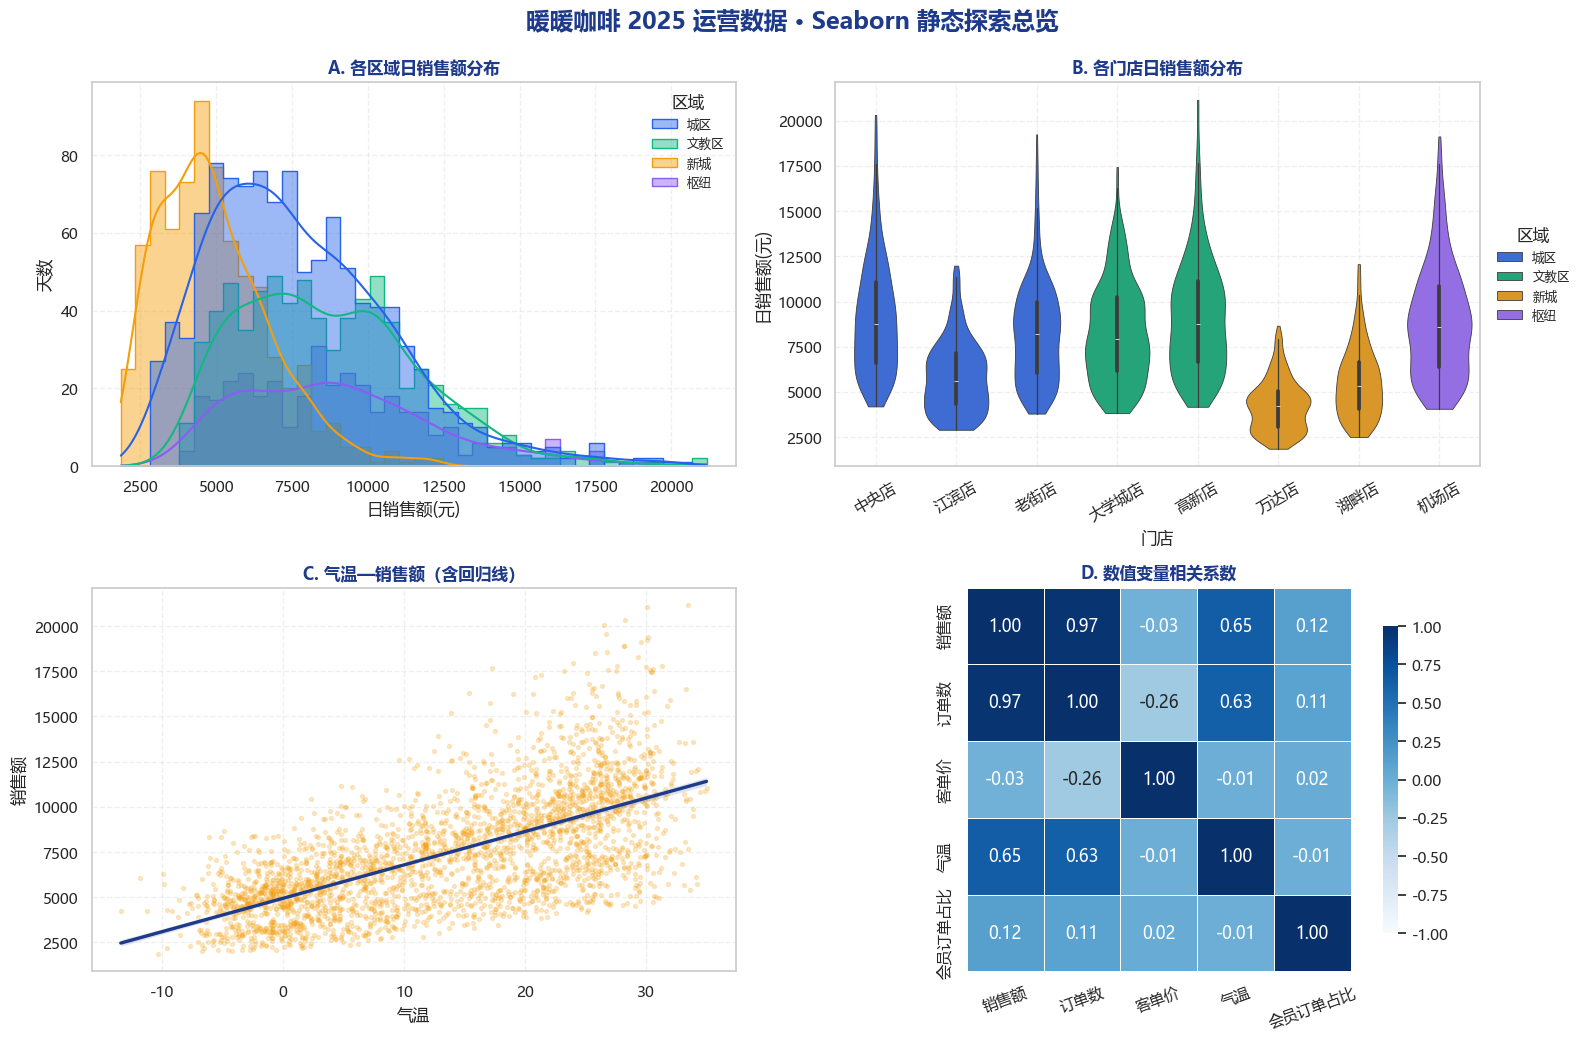

In [11]:
# ===== 综合①：Seaborn 静态探索总览（2×2，300 dpi）=====
fig, axes = plt.subplots(2, 2, figsize=(16, 10.5))

sns.histplot(data=df, x='销售额', hue='区域', palette=REGION_COLORS, bins=40, kde=True,
             element='step', fill=True, alpha=.45, ax=axes[0, 0], legend=True)
axes[0, 0].set_title('A. 各区域日销售额分布', fontsize=12, fontweight='bold', color=NAVY)
axes[0, 0].set_xlabel('日销售额(元)'); axes[0, 0].set_ylabel('天数')
sns.move_legend(axes[0, 0], 'upper right', frameon=False, title='区域', fontsize=9)

sns.violinplot(data=df, x='门店', y='销售额', hue='区域', palette=REGION_COLORS, order=STORE_ORDER,
               cut=0, inner='box', linewidth=.6, ax=axes[0, 1], legend=True)
axes[0, 1].set_title('B. 各门店日销售额分布', fontsize=12, fontweight='bold', color=NAVY)
axes[0, 1].tick_params(axis='x', rotation=30)
axes[0, 1].set_xlabel('门店'); axes[0, 1].set_ylabel('日销售额(元)')
sns.move_legend(axes[0, 1], 'center left', bbox_to_anchor=(1.01, .5), frameon=False, title='区域', fontsize=9)

sns.regplot(data=df, x='气温', y='销售额', ax=axes[1, 0],
            scatter_kws={'s': 8, 'alpha': .22, 'color': AMBER},
            line_kws={'color': NAVY, 'lw': 2.4})
axes[1, 0].set_title('C. 气温—销售额（含回归线）', fontsize=12, fontweight='bold', color=NAVY)

corr = df[['销售额', '订单数', '客单价', '气温', '会员订单占比']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues', square=True, vmin=-1, vmax=1,
            linewidths=.5, linecolor='white', ax=axes[1, 1], cbar_kws={'shrink': .8})
axes[1, 1].set_title('D. 数值变量相关系数', fontsize=12, fontweight='bold', color=NAVY)
axes[1, 1].tick_params(axis='x', rotation=20)

for ax in axes.ravel():
    ax.grid(True, linestyle='--', alpha=.3)
fig.suptitle('暖暖咖啡 2025 运营数据 · Seaborn 静态探索总览', fontsize=17, fontweight='bold', color=NAVY, y=.99)
fig.tight_layout()

fig.savefig(OUT / 'dashboard_static.png', dpi=300, bbox_inches='tight')
plt.show()

In [12]:
# ===== 综合② 进阶 p5：HeatMap 门店 × 月份（万元）=====
hm_df = df.pivot_table(index='门店', columns='月份', values='销售额', aggfunc='sum').reindex(STORE_ORDER) / 1e4
months_x = [f'{m}月' for m in hm_df.columns]
hm_data = [[mi, si, round(hm_df.iloc[si, mi], 1)]
           for si in range(len(STORE_ORDER)) for mi in range(len(months_x))]

heat = (
    HeatMap(init_opts=opts.InitOpts(theme=ThemeType.MACARONS, width='100%', height='480px'))
    .add_xaxis(months_x)
    .add_yaxis('销售额(万元)', STORE_ORDER, hm_data,
               label_opts=opts.LabelOpts(is_show=True, font_size=9))
    .set_global_opts(
        title_opts=opts.TitleOpts(title='门店 × 月份销售额热力图', subtitle='单位：万元'),
        xaxis_opts=opts.AxisOpts(name='月份', name_location='middle', name_gap=30,
                                 splitarea_opts=opts.SplitAreaOpts(is_show=True)),
        yaxis_opts=opts.AxisOpts(name='门店', name_location='middle', name_gap=46, is_inverse=True,
                                 splitarea_opts=opts.SplitAreaOpts(is_show=True)),
        visualmap_opts=opts.VisualMapOpts(min_=float(hm_df.values.min()), max_=float(hm_df.values.max()),
                                          is_calculable=True, orient='vertical',
                                          pos_right='3%', pos_top='middle',
                                          range_color=['#EFF6FF', '#BFDBFE', '#93C5FD', '#3B82F6', '#1E3A8A']),
        tooltip_opts=opts.TooltipOpts(formatter='{b}<br/>{a0}: {c}'),
        legend_opts=opts.LegendOpts(is_show=False),
    )
)
heat.render(str(OUT / 'p5_heatmap.html'))
print('已导出', OUT / 'p5_heatmap.html')
print('单店单月最高:', hm_df.stack().idxmax(), round(hm_df.stack().max(), 1), '万元')

已导出 exp3_assets\p5_heatmap.html
单店单月最高: ('中央店', 7) 39.3 万元


In [13]:
# ===== 综合② 进阶 p6：Radar 各区域多维对比 =====
rad = df.groupby('区域').agg(
    日均销售额=('销售额', 'mean'), 客单价=('客单价', 'mean'),
    日均订单数=('订单数', 'mean'), 会员占比=('会员订单占比', 'mean'),
).reindex(REGION_ORDER)
rad['会员占比'] *= 100
rad['促销日占比'] = df.groupby('区域')['是否促销'].apply(lambda s: (s == '是').mean() * 100).reindex(REGION_ORDER)

indicators = [
    opts.RadarIndicatorItem(name='日均销售额(元)', max_=9500),
    opts.RadarIndicatorItem(name='客单价(元)', max_=52),
    opts.RadarIndicatorItem(name='日均订单数', max_=230),
    opts.RadarIndicatorItem(name='会员占比(%)', max_=40),
    opts.RadarIndicatorItem(name='促销日占比(%)', max_=22),
]

radar = Radar(init_opts=opts.InitOpts(theme=ThemeType.MACARONS, width='100%', height='480px'))
radar.add_schema(schema=indicators, shape='polygon', center=['50%','57%'], radius=['22%','60%'],
                 splitarea_opt=opts.SplitAreaOpts(is_show=True, areastyle_opts=opts.AreaStyleOpts(opacity=.12)),
                 textstyle_opts=opts.TextStyleOpts(font_size=10))
for rg in REGION_ORDER:
    row = rad.loc[rg, ['日均销售额', '客单价', '日均订单数', '会员占比', '促销日占比']]
    radar.add(rg, [[round(float(v), 1) for v in row]], color=REGION_COLORS[rg],
              linestyle_opts=opts.LineStyleOpts(width=2),
              areastyle_opts=opts.AreaStyleOpts(opacity=.18))
radar.set_series_opts(label_opts=opts.LabelOpts(is_show=False))
radar.set_global_opts(
    title_opts=opts.TitleOpts(title='各区域经营多维雷达图', subtitle='销售额 / 客单价 / 客流 / 会员 / 促销'),
    legend_opts=opts.LegendOpts(pos_bottom='0%'),
    tooltip_opts=opts.TooltipOpts(trigger='item'),
)
radar.render(str(OUT / 'p6_radar.html'))
print('已导出', OUT / 'p6_radar.html')
print(rad.round(2).to_string())

已导出 exp3_assets\p6_radar.html
       日均销售额    客单价   日均订单数   会员占比  促销日占比
区域                                       
城区   7757.94  46.93  164.74  34.99  16.53
文教区  8716.69  41.85  209.07  35.17  16.03
新城   4911.21  49.35  100.50  35.18  18.90
枢纽   8920.34  46.44  192.11  34.66  18.36


In [14]:
# ===== 综合③：Page 组合看板（六图同页，一行换肤）=====
page = Page(layout=Page.SimplePageLayout, page_title='暖暖咖啡 2025 运营数据看板')
page.add(heat, line, bar, pie, sc, radar)
page.render(str(OUT / 'dashboard_combo.html'))
print('已导出', OUT / 'dashboard_combo.html')
print('看板包含: 门店×月份热力图 / 月度趋势折线 / 门店柱状 / 品类圆环 / 气温散点 / 区域雷达')

已导出 exp3_assets\dashboard_combo.html
看板包含: 门店×月份热力图 / 月度趋势折线 / 门店柱状 / 品类圆环 / 气温散点 / 区域雷达


### 数据故事解读

1. **气温型旺季**：气温相关 0.651，7 月 257.4 万（2 月的 2.33 倍），5 月启动、6–8 月见顶。
2. **区域差异在基数**：四区峰值同落 7–8 月；新城日均 4911 元仅为枢纽的 56%，且最窄（σ≈1845）。
3. **靠客流不靠提价**：销售额↔订单数 0.966、↔客单价 −0.026；促销是“多来一次”而非“每单更多”。
4. **促销有时窗**：整体 +41.6%，10–20℃ 最高（44%），极冷与 >30℃ 递减。
5. **结构短板**：咖啡+周边 59.7% 双主力，甜品仅 17.0%；重点改造新城两家弱店与甜品。

**产出**：`exp3_assets/dashboard_static.png`（300 dpi）、`exp3_assets/dashboard_combo.html`。

## 思考题

**1. 同一份数据如何同时支撑 Seaborn 与 Pyecharts？**
只读一次 CSV，统一清洗并固定 `STORE_ORDER` / `REGION_COLORS`；`groupby` 聚合后的结果一端给 Seaborn 出统计结论，另一端转 list 喂 Pyecharts。同一口径与配色下，T2 中位排序、T6 柱高、雷达轴长互相印证。

**2. 何时选交互图？DataZoom / 图例切换解决了什么？**
读者需要自己提问（下钻、异常排查、多系列对比、Web 看板）时用交互。DataZoom 解决全局与局部：T5 框选 5–9 月比旺季位次，T8 放大 30℃ 以上看促销上沿；图例切换解决多系列遮挡（T7 只看某品类）。论文插图与确定性打印仍用静态图。

**3. 小提琴图与箱线图各答什么问题？**
箱线用 5 个统计量答“位置、离散、离群”，跨组快且不假设分布；小提琴叠加 KDE 答“形状”：单峰/多峰、密度集中与尾部。本实验两店主箱线几乎同高，小提琴才显出饱满纺锤 vs 低位单薄。样本 <20 时退回箱线或散点。

**4. 看板怎样“讲故事”而非堆图？**
先提问后选图（分布→单店→驱动→节奏→结构→画像，一图一问）；视觉编码固定（橙=促销、蓝=非促销、区域色贯穿）；收尾落到行动（哪家店弱、哪个品类短板、促销投在哪个温度窗）。
